#### Implement the linear random walk problem of Figure 9.1, with state aggregation

With state aggragation, states at [1,99], [100,199] etc are lumped together. 
1. (20 pts) Define number of features (k) there are, and initialize the weights w to an numpy array of than length.

In [1]:
import numpy as np

n_states = 1000      # states numbered 1..1000
group_size = 100     # states per aggregated group

k = n_states // group_size   # number of features = 10
w = np.zeros(k)              # one weight per group, initialized to 0

print(k)   # 10
print(w)   # [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

10
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


2. (30 pts) Implement the feature() function by state aggregation:  for each state s between 1 to 999, get the 1-hot encoding vector of length k, where at position int(s/100) the 1-hot vector is 1, else it's zero. Returning this numpy 1-hot vector.

In [2]:
def feature(s):
    x = np.zeros(k)          # length-k vector of zeros
    x[int(s / 100)] = 1      # set the group's position to 1
    return x



3.  (20 pts) Define the v() function by product of the weights and features, also an eval_v utility function that returns $w^T x$.

In [3]:

import numpy as np
import gymnasium as gym
class RandomWalk1000_discrete(gym.Env):
    def __init__(self, start_state = 500, episodes = 10, alpha = 0.1, gamma = 1.0, right_boundary = 999, left_boundary = 1):
        self.start_state = start_state
        self.episode = episodes
        self.alpha = alpha
        self.left_boundary = left_boundary
        self.right_boundary = right_boundary
        # $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$
        # Define number of features, and the length of the array of linear approximation parameters
        self.k = 10
        self.w = np.zeros(self.k)
        self.neighbor_range = 100
        self.gamma = gamma

    def step(self, s): # Return reward, new state, done

        action = np.random.choice(list(range(-self.neighbor_range, 0)) + list(range(1, self.neighbor_range + 1)))
 
        ss = s + action
        
        if ss < self.left_boundary:
            return (-1.0, self.left_boundary - 1, True) #terminate at left boundary
        elif ss > self.right_boundary: 
            return (1.0, self.right_boundary + 1, True) #terminate at right boundary
        else:
            return (0.0, ss, False)  # Continue walking
        
    def v(self, s): # the linear approximation function
        # $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$
        return self.w @ self.features(s)  
    
    def eval_v(self, w, s): # for evaluation using stored w
        # $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$
        return w @ self.features(s)

    def features(self, s): #scaling is very important, else has to use tiny step size or risk blow up
        # $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$
        x = np.zeros(self.k)          # length-k vector of zeros
        x[int(s / 100)] = 1      # set the group's position to 1
        return x    

    def TD0(self):
        for ep in range(self.episode):
            s = self.start_state
            done = False
            while not done:
                x = self.features(s)
                R, ss, done = self.step(s)
                target = R + self.gamma*(0.0 if done else self.v(ss))
                delta = target - self.v(s)
                self.w += self.alpha * delta * x
                s = ss


4. (20 pts) Do two runs of TD0 to get value function approximation, one with 1k episode, and one with 1k episode

In [4]:
# $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$    
rw_100 = RandomWalk1000_discrete(episodes = 100)
rw_100.TD0()

rw_1k = RandomWalk1000_discrete(episodes = 1000)
rw_1k.TD0()


5. (20 pts) Plot the two function approximations, as well as the RMSE with the theoretical state value

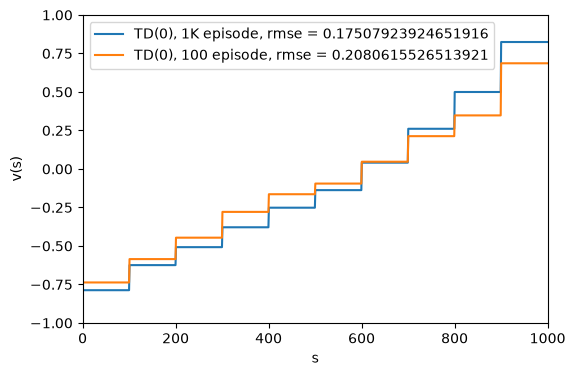

In [7]:
# look at the linear approximation function over the episodes, the linear function move around quite 
# a bit towards the end
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider

x = np.linspace(1, 999, 1000)
w_1k = rw_1k.w
w_100 = rw_100.w
def f(rw, x, w):
    return np.array([rw.eval_v(w, xx) for xx in x])
ground_truth = -1 + 2*x/1000  #<======== this is the griund truth v(s)

plt.figure(figsize=(6,4))
v_1k = f(rw_1k, x, w_1k)
# $$$$$$$$$$$$$$$$ ADD CODE $$$$$$$$$$$$$$$$$$    
rmse_1k = np.sqrt(np.mean((v_1k - ground_truth) ** 2)) 
v_100 = f(rw_100, x, w_100)
rmse_100 = np.sqrt(np.mean((v_100 - ground_truth) ** 2))

plt.plot(x, v_1k, label = f"TD(0), 1K episode, rmse = {rmse_1k}")
plt.plot(x, v_100, label = f"TD(0), 100 episode, rmse = {rmse_100}")
plt.xlim(0, 1000)
plt.ylim(-1, 1)
plt.xlabel("s")
plt.ylabel("v(s)")
plt.legend()
plt.show()


In [8]:
! python -m jupyter nbconvert 09_value_function_approximation_hw.ipynb --to webpdf

[NbConvertApp] Converting notebook 09_value_function_approximation_hw.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 125213 bytes to 09_value_function_approximation_hw.pdf


The text below is unchanged except for Step 4, where the value error is now written with the indicator function directly and $\mu$ no longer appears.

## Step 1: The problem

There is a line of states $s = 1, 2, \dots, 999$, and every episode starts at $s_0 = 500$. On each step, the walker jumps by a random amount $a$:

$$
a \sim \text{Uniform}\{-100, \dots, -1,\ 1, \dots, 100\}, \qquad s' = s + a
$$

There are 200 possible jumps, each with probability $\tfrac{1}{200}$. The episode ends when the walker leaves the line:

$$
s' < 1 \ \Rightarrow\ \text{terminate left, reward } -1, \qquad s' > 999 \ \Rightarrow\ \text{terminate right, reward } +1
$$

Every other step gives reward 0.

The question is: **starting from state $s$, what total reward do you expect?** That number is the value of $s$.

## Step 2: Modeling it as reinforcement learning

**States** are $\mathcal{S} = \{1, \dots, 999\}$, plus the terminal states 0 and 1000.

**Policy.** The walker makes no decisions, because the jump is pure randomness. In RL terms, a fixed policy $\pi$ is followed and we only want to evaluate it. This is a **prediction problem**, not a control problem. In the code, `action` in `step()` is really just this environment randomness.

**Transition and reward.** These are exactly the rules in Step 1.

**Return.** The return is the total future reward from time $t$:

$$
G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots
$$

Here $R_{t+1}$ is the reward received after the step from time $t$, and $\gamma \in [0,1]$ is the discount factor. In this problem $\gamma = 1$, so all rewards count fully.

**Value function.** The value of a state is its expected return:

$$
v_\pi(s) = \mathbb{E}_\pi[\,G_t \mid S_t = s\,]
$$

Since the only nonzero reward is the final ±1 and $\gamma = 1$, the return is exactly +1 or −1. This gives a clean meaning to the value:

$$
v_\pi(s) = (+1)\,P(\text{right} \mid s) + (-1)\,P(\text{left} \mid s) = 2\,P(\text{right} \mid s) - 1
$$

The chance of exiting right grows roughly linearly with $s$, so

$$
v_\pi(s) \approx -1 + \frac{2s}{1000}
$$

That's the `ground_truth` line in your plot.

**Where this line comes from.** The derivation has three parts.

*The interior equation.* For a state far from both edges, every jump stays inside and gives reward 0. With $\gamma = 1$, the Bellman equation says the value of $s$ is the plain average of its 200 neighbors' values:

$$
v_\pi(s) = \frac{1}{200}\sum_{\substack{a=-100\\a\neq 0}}^{100} v_\pi(s+a)
$$

*Which functions satisfy it.* Expand each neighbor with a Taylor series:

$$
v_\pi(s+a) \approx v_\pi(s) + a\,v_\pi'(s) + \frac{a^2}{2}\,v_\pi''(s)
$$

Average over the 200 jumps. The first term stays $v_\pi(s)$. The second term averages to 0, because the jumps are symmetric: $\frac{1}{200}\sum a = 0$. The third term averages to $\frac{1}{2}\cdot\frac{1}{200}\sum a^2 \cdot v_\pi''(s) = 1691.75\,v_\pi''(s)$. So

$$
v_\pi(s) \approx v_\pi(s) + 0 + 1691.75\,v_\pi''(s) \quad\Longrightarrow\quad v_\pi''(s) = 0 \quad\Longrightarrow\quad v_\pi(s) = c_1 + c_2\,s
$$

Zero second derivative means a straight line. This holds exactly, not just approximately: plugging a line into the interior equation gives $c_1 + c_2 s + c_2\cdot\frac{1}{200}\sum a = c_1 + c_2 s$.

*Fixing the line with the boundaries.* Treat exiting left as landing at $s = 0$ with return −1, and exiting right as landing at $s = 1000$ with return +1:

$$
v_\pi(0) = -1, \quad v_\pi(1000) = +1 \quad\Longrightarrow\quad c_1 = -1,\ \ c_2 = \frac{2}{1000}
$$

That gives $v_\pi(s) \approx -1 + \frac{2s}{1000}$.

*Why "≈".* The walk overshoots the edges, but every left exit returns exactly −1 and every right exit exactly +1, however far past the edge it lands. The line would give those landings more extreme values (for example, −1.1 at $s = -50$). So states within 100 of either end are pulled toward 0, which is the slight bend toward horizontal at both ends of Figure 9.1. The exact $v_\pi$ comes from solving the full Bellman equation, with the edge terms included, as a 999×999 linear system $(I - P)\mathbf{v} = \mathbf{b}$.

**Goal:** learn $v_\pi(s)$ from simulated episodes alone, without using the formula.

## Step 3: Approximating the value with a few parameters

A table would need 999 separate numbers, each learned only when its own state is visited. Instead, we approximate the value with $k = 10$ weights:

$$
\hat{v}(s, \mathbf{w}) = \mathbf{w}^\top \mathbf{x}(s)
$$

The pieces are:
- $\mathbf{w} \in \mathbb{R}^{10}$ is the parameter vector we learn (`self.w`).
- $\mathbf{x}(s) \in \mathbb{R}^{10}$ is the feature vector of $s$ (`features(s)`).

With state aggregation, $\mathbf{x}(s)$ is one-hot at index $\lfloor s/100 \rfloor$, so

$$
\hat{v}(s, \mathbf{w}) = w_{\lfloor s/100 \rfloor}
$$

All 100 states in a group share one weight. Learning about state 250 therefore also updates the estimate for state 299, and that sharing is the generalization. The cost is the staircase shape: a constant can't follow a sloped line within a group.

## Step 4: What "learning" minimizes

We want $\hat{v}$ close to $v_\pi$, weighted by how often each state is visited. This is the value error:

$$
\overline{\text{VE}}(\mathbf{w}) = \sum_{s} \frac{\mathbb{E}\left[\displaystyle\sum_{t=0}^{T-1} \mathbb{1}\{S_t = s\}\right]}{\mathbb{E}[T]}\,\big[v_\pi(s) - \hat{v}(s,\mathbf{w})\big]^2
$$

The pieces are:
- $\mathbb{1}\{S_t = s\}$ is 1 if the walker is in state $s$ at time $t$, and 0 otherwise.
- $T$ is the termination time.
- The fraction is the share of time steps spent in state $s$.

We minimize it by **stochastic gradient descent**: each time we visit a state $S_t$, we take one gradient step on that state's squared error. To make the derivative clean, write the error with a factor of $\tfrac12$:

$$
\tfrac{1}{2}\big[v_\pi(S_t) - \hat{v}(S_t,\mathbf{w})\big]^2
$$

Its gradient with respect to $\mathbf{w}$ is

$$
-\big[v_\pi(S_t) - \hat{v}(S_t,\mathbf{w})\big]\,\nabla_{\mathbf{w}}\hat{v}(S_t,\mathbf{w})
$$

For a linear function, $\nabla_{\mathbf{w}}\hat{v}(s,\mathbf{w}) = \mathbf{x}(s)$. Stepping against the gradient with step size $\alpha$ gives

$$
\mathbf{w} \leftarrow \mathbf{w} + \alpha\,\big[v_\pi(S_t) - \hat{v}(S_t,\mathbf{w})\big]\,\mathbf{x}(S_t)
$$

The problem is that we don't know $v_\pi(S_t)$, since that's what we're trying to learn.

## Step 5: Replacing the unknown with a TD(0) target

We replace $v_\pi(S_t)$ with something we can compute after a single step:

$$
U_t = R_{t+1} + \gamma\,\hat{v}(S_{t+1}, \mathbf{w})
$$

This target is "the reward I just got, plus my current estimate of where I landed." It's justified by the one-step recursion of the value function:

$$
v_\pi(s) = \mathbb{E}\big[R_{t+1} + \gamma\, v_\pi(S_{t+1}) \mid S_t = s\big]
$$

If the next state is terminal, its value is 0, so $U_t = R_{t+1}$.

Define the **TD error** as the difference between the target and the current estimate:

$$
\delta_t = U_t - \hat{v}(S_t, \mathbf{w})
$$

The update becomes

$$
\mathbf{w} \leftarrow \mathbf{w} + \alpha\,\delta_t\,\mathbf{x}(S_t)
$$

This is called **semi-gradient** TD(0). The target $U_t$ itself depends on $\mathbf{w}$, but we treat it as a fixed number when differentiating.

Because $\mathbf{x}(S_t)$ is one-hot, only one weight changes per step:

$$
w_g \leftarrow w_g + \alpha\,\delta_t, \qquad g = \lfloor S_t/100 \rfloor
$$

Here is how each line of `TD0()` maps to the math:

| Code | Math |
|---|---|
| `x = self.features(s)` | $\mathbf{x}(S_t)$ |
| `R, ss, done = self.step(s)` | sample $R_{t+1}, S_{t+1}$ |
| `target = R + self.gamma*(0.0 if done else self.v(ss))` | $U_t$ |
| `delta = target - self.v(s)` | $\delta_t$ |
| `self.w += self.alpha * delta * x` | $\mathbf{w} \leftarrow \mathbf{w} + \alpha\,\delta_t\,\mathbf{x}(S_t)$ |

## Step 6: Checking the result

After training, compare $\hat{v}$ with the ground truth using

$$
\text{RMSE} = \sqrt{\frac{1}{N}\sum_{j=1}^{N}\big(\hat{v}(x_j,\mathbf{w}) - v_\pi(x_j)\big)^2}
$$

The plot shows 10 steps climbing roughly along the line $-1 + 2s/1000$. That's what a correct solution looks like.

To summarize the whole pipeline in one line: **simulate episodes → after each step, nudge one group's weight toward "reward + next estimate" → the 10 weights settle into a staircase approximating $v_\pi$.**